# 01 · Data Preparation and Exploratory Analysis

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Souhaila-DJAFFAL/longtail-recsys/blob/main/notebooks/01_data_preparation_and_eda.ipynb)

**Goal.** Turn raw MovieLens-1M ratings into chronological user histories, split them for
evaluation, and quantify the **long-tail popularity structure** that the rest of the project studies.

| Step | What happens |
|---|---|
| 1 | Download MovieLens-1M (1M ratings, 6,040 users, ~3,700 movies) |
| 2 | Treat every rating as an implicit positive interaction and apply 5-core filtering |
| 3 | Leave-one-out split per user: last item → test, second-to-last → validation |
| 4 | Explore the item-popularity distribution (head vs. long tail) |
| 5 | Save the processed dataset for the next notebooks |

In [1]:
# --- Setup: works locally (Jupyter) and on Google Colab ---
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.exists("02_models.ipynb"):
    !git clone -q https://github.com/Souhaila-DJAFFAL/longtail-recsys.git
    %cd longtail-recsys/notebooks
    !pip install -q tabulate

DATASET = os.environ.get("RECSYS_DATASET", "ml-1m")  # "ml-1m" (real) or "synthetic" (fast check)
QUICK = os.environ.get("RECSYS_QUICK", "0") == "1"     # few epochs, for smoke tests only
ARTIFACTS, RESULTS = "../artifacts", "../results"
os.makedirs(ARTIFACTS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

/content/longtail-recsys/notebooks


In [2]:
import io, pickle, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Load the raw interactions

MovieLens-1M is downloaded from the official [GroupLens](https://grouplens.org/datasets/movielens/1m/) site
(free for research use; the data is not redistributed in this repository).

A small **synthetic** dataset with the same structure (Zipf-distributed item popularity and
genre-driven sequential behaviour) is available for fast checks by setting `RECSYS_DATASET=synthetic`.

In [3]:
ML1M_URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"


def download_ml1m(data_dir="../data"):
    """Download MovieLens-1M once and return (user, item, timestamp) rows."""
    os.makedirs(data_dir, exist_ok=True)
    path = os.path.join(data_dir, "ml-1m", "ratings.dat")
    if not os.path.exists(path):
        print("Downloading MovieLens-1M ...")
        with urllib.request.urlopen(ML1M_URL) as resp:
            zipfile.ZipFile(io.BytesIO(resp.read())).extractall(data_dir)
    df = pd.read_csv(path, sep="::", engine="python", names=["user", "item", "rating", "ts"])
    return df[["user", "item", "ts"]]


def synthetic_interactions(n_users=300, n_items=400, n_genres=8, min_len=10, max_len=60,
                           stay_prob=0.75, zipf_a=1.1, seed=0):
    """Synthetic long-tail data: Zipf popularity within genres, users prefer two genres,
    consecutive items tend to stay in the same genre (sequential signal)."""
    rng = np.random.default_rng(seed)
    genre_of = rng.integers(0, n_genres, size=n_items)
    genre_items = [np.where(genre_of == g)[0] for g in range(n_genres)]
    genre_probs = [(w := 1.0 / np.arange(1, len(it) + 1) ** zipf_a) / w.sum() for it in genre_items]
    rows = []
    for u in range(n_users):
        prefs = rng.choice(n_genres, size=2, replace=False)
        length, g, seen, t = int(rng.integers(min_len, max_len + 1)), int(rng.choice(prefs)), set(), 0
        while len(seen) < length:
            if rng.random() > stay_prob:
                g = int(rng.choice(prefs)) if rng.random() < 0.8 else int(rng.integers(n_genres))
            i = int(rng.choice(genre_items[g], p=genre_probs[g]))
            if i not in seen:
                seen.add(i)
                rows.append((u, i, t))
                t += 1
    return pd.DataFrame(rows, columns=["user", "item", "ts"])


raw = download_ml1m() if DATASET == "ml-1m" else synthetic_interactions()
print(f"{DATASET}: {len(raw):,} interactions, {raw.user.nunique():,} users, {raw.item.nunique():,} items")
raw.head()

ml-1m: 1,000,209 interactions, 6,040 users, 3,706 items


,user,item,ts
0,1,1193,978300760
1,1,661,978302109
2,1,914,978301968
3,1,3408,978300275
4,1,2355,978824291


## 2. Implicit feedback, 5-core filtering and leave-one-out split

* **Implicit feedback.** Production recommenders learn mostly from clicks, views and purchases rather
  than star ratings, so every rating is treated as a positive interaction.
* **5-core filtering.** Users and items with fewer than 5 interactions are removed iteratively, a
  standard step that keeps every user's history long enough to split.
* **Ids.** Items are re-indexed to `1..n_items`; index `0` is reserved for padding in the sequential model.
* **Leave-one-out split.** Each user's history is sorted by time: the **last** item is the test target,
  the **second-to-last** is the validation target, and everything before is training data. This mimics
  predicting a user's next interaction.

In [4]:
def k_core(df, k=5):
    """Iteratively keep users and items with at least k interactions."""
    while True:
        keep = (df.groupby("user")["item"].transform("size") >= k) & \
               (df.groupby("item")["user"].transform("size") >= k)
        if keep.all():
            return df
        df = df[keep]


def build_dataset(df, min_count=5):
    df = k_core(df.drop_duplicates(["user", "item"]), min_count)
    df = df.sort_values(["user", "ts"], kind="mergesort")   # stable: keeps file order on ties
    item_ids = {it: i + 1 for i, it in enumerate(sorted(df["item"].unique()))}
    user_ids = {us: i for i, us in enumerate(sorted(df["user"].unique()))}
    df = df.assign(item=df["item"].map(item_ids), user=df["user"].map(user_ids))
    seqs = df.groupby("user")["item"].apply(list)

    n_users, n_items = len(user_ids), len(item_ids)
    train = [seqs[u][:-2] for u in range(n_users)]
    valid = np.array([seqs[u][-2] for u in range(n_users)])
    test = np.array([seqs[u][-1] for u in range(n_users)])
    item_pop = np.zeros(n_items + 1, dtype=np.int64)       # popularity = training interactions only
    for s in train:
        np.add.at(item_pop, s, 1)
    return {"n_users": n_users, "n_items": n_items, "train": train,
            "valid": valid, "test": test, "item_pop": item_pop}


data = build_dataset(raw)
n_train = sum(len(s) for s in data["train"])
lengths = np.array([len(s) + 2 for s in data["train"]])
stats = pd.Series({
    "users": data["n_users"], "items": data["n_items"],
    "interactions (after 5-core)": int(lengths.sum()),
    "training interactions": n_train,
    "density": f"{lengths.sum() / (data['n_users'] * data['n_items']):.2%}",
    "median history length": int(np.median(lengths)),
}, name=DATASET)
stats.to_frame()

,ml-1m
users,6040
items,3416
interactions (after 5-core),999611
training interactions,987531
density,4.84%
median history length,96


## 3. The long tail

Item popularity in interaction data is highly skewed: a small **head** of items attracts most
interactions while the large **tail** receives few. Throughout the project, the head is defined as the
**top 20% of items by training popularity**; all other items form the tail.

A recommender trained on such data tends to amplify this skew (popularity bias), which reduces
catalogue coverage and under-serves users with niche tastes.

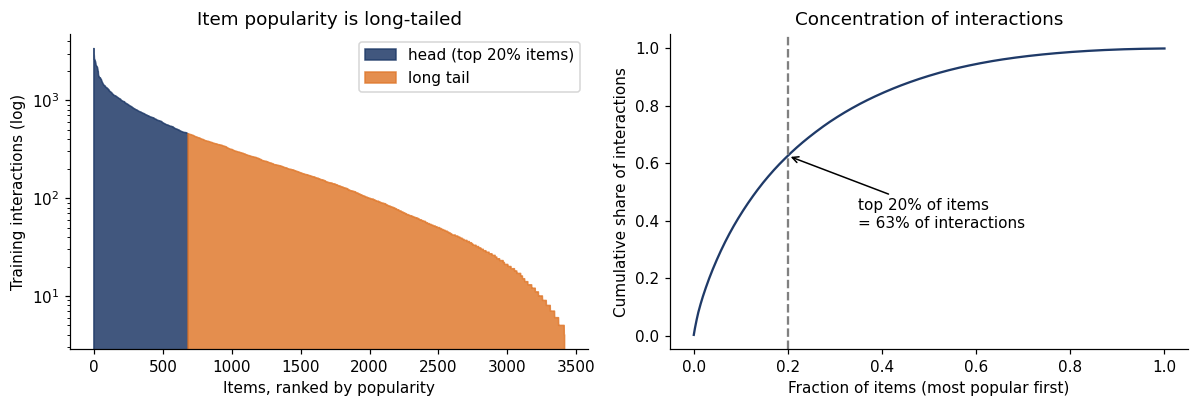

Head items: 683 of 3,416; they receive 62.7% of training interactions.


In [5]:
pop = data["item_pop"][1:]
order = np.argsort(-pop)
sorted_pop = pop[order]
n_head = int(round(0.2 * data["n_items"]))
head_share = sorted_pop[:n_head].sum() / sorted_pop.sum()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
ax = axes[0]
ax.fill_between(np.arange(n_head), sorted_pop[:n_head], color="#1f3a68", alpha=0.85, label="head (top 20% items)")
ax.fill_between(np.arange(n_head, len(pop)), sorted_pop[n_head:], color="#e07a2f", alpha=0.85, label="long tail")
ax.set_yscale("log")
ax.set_xlabel("Items, ranked by popularity")
ax.set_ylabel("Training interactions (log)")
ax.set_title("Item popularity is long-tailed")
ax.legend()

ax = axes[1]
cum = np.cumsum(sorted_pop) / sorted_pop.sum()
ax.plot(np.arange(1, len(pop) + 1) / len(pop), cum, color="#1f3a68")
ax.axvline(0.2, ls="--", color="grey")
ax.annotate(f"top 20% of items\n= {head_share:.0%} of interactions", (0.2, head_share),
            xytext=(0.35, head_share - 0.25), arrowprops={"arrowstyle": "->"})
ax.set_xlabel("Fraction of items (most popular first)")
ax.set_ylabel("Cumulative share of interactions")
ax.set_title("Concentration of interactions")
fig.tight_layout()
fig.savefig(f"{RESULTS}/eda_long_tail.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Head items: {n_head:,} of {data['n_items']:,}; they receive {head_share:.1%} of training interactions.")

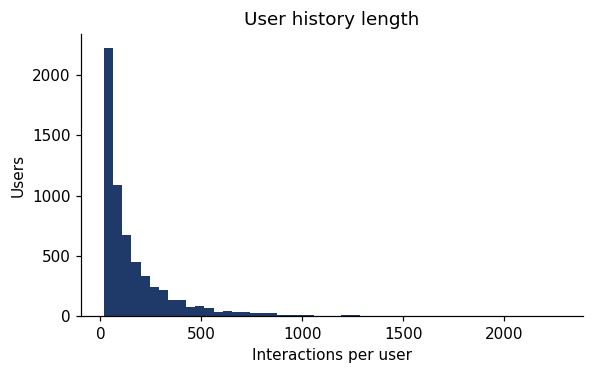

41.7% of users have a long-tail item as their test target: a model that only recommends popular items cannot serve them.


In [6]:
is_head = np.zeros(data["n_items"] + 1, dtype=bool)
is_head[order[:n_head] + 1] = True
tail_test = (~is_head[data["test"]]).mean()

fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.hist(lengths, bins=50, color="#1f3a68")
ax.set_xlabel("Interactions per user")
ax.set_ylabel("Users")
ax.set_title("User history length")
fig.tight_layout()
plt.show()
print(f"{tail_test:.1%} of users have a long-tail item as their test target: "
      "a model that only recommends popular items cannot serve them.")

## 4. Save the processed dataset

In [7]:
with open(f"{ARTIFACTS}/dataset_{DATASET}.pkl", "wb") as f:
    pickle.dump(data, f)
print("saved", f"{ARTIFACTS}/dataset_{DATASET}.pkl")

saved ../artifacts/dataset_ml-1m.pkl


**Next:** [`02_models.ipynb`](02_models.ipynb) defines the three recommenders.